# Phần IV — Bài 1: Cửa hàng tạp hóa (6 giao dịch)

Với **min_sup = 33,33%** và **min_conf = 60%**, tìm tập phổ biến, luật kết hợp và trực quan hóa giống phần hướng dẫn chung.

**Họ tên:** Nguyễn Lộc  \n**MSSV:** 6451071043  \n**Nguồn đề:** *Tàu liệu LAB1.pdf*, trang 43–45.  \n**Dữ liệu:** nhập trực tiếp từ bảng trong PDF; không cần tải thêm file.

> Chạy **Runtime → Run all** trên Colab. Mỗi notebook độc lập và có lệnh in họ tên/MSSV.

In [1]:
HO_TEN='NGUYỄN LỘC'
MSSV='6451071043'
print(f'Họ tên: {HO_TEN} | MSSV: {MSSV}')

Họ tên: NGUYỄN LỘC | MSSV: 6451071043


In [2]:
from itertools import combinations
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def support_count(transactions, itemset):
    s=set(itemset)
    return sum(s.issubset(set(t)) for t in transactions)

def apriori_manual(transactions, min_support_count):
    """Thuật toán Apriori: join + prune ở mỗi mức k."""
    transactions=[frozenset(t) for t in transactions]
    n=len(transactions)
    all_items=sorted(set().union(*transactions))
    candidates=[frozenset([x]) for x in all_items]
    levels=[]; counts={}
    k=1
    while candidates:
        level={c:support_count(transactions,c) for c in candidates}
        frequent={c:cnt for c,cnt in level.items() if cnt>=min_support_count}
        if not frequent: break
        levels.append(frequent)
        counts.update(frequent)
        prev=set(frequent)
        candidate_next=set()
        for a,b in combinations(sorted(prev,key=lambda z:tuple(sorted(z))),2):
            merged=a|b
            if len(merged)==k+1 and all(frozenset(s) in prev for s in combinations(merged,k)):
                candidate_next.add(merged)
        candidates=sorted(candidate_next,key=lambda x:tuple(sorted(x)))
        k+=1
    return levels,counts

def itemsets_table(counts,n):
    rows=[{'k':len(items),'Tập phổ biến':', '.join(sorted(items)), 'Support count':cnt, 'Support':round(cnt/n,5)} for items,cnt in counts.items()]
    return pd.DataFrame(rows).sort_values(['k','Tập phổ biến']).reset_index(drop=True) if rows else pd.DataFrame(columns=['k','Tập phổ biến','Support count','Support'])

def rules_from_counts(counts, transactions, min_conf, *, target_prefix=None):
    n=len(transactions)
    rows=[]
    for whole,both_count in counts.items():
        if len(whole)<2: continue
        for size in range(1,len(whole)):
            for left_tuple in combinations(sorted(whole),size):
                left=frozenset(left_tuple)
                right=whole-left
                if target_prefix is not None and not (len(right)==1 and next(iter(right)).startswith(target_prefix)):
                    continue
                left_count=support_count(transactions,left)
                right_count=support_count(transactions,right)
                conf=both_count/left_count
                if conf+1e-12>=min_conf:
                    rows.append({'Vế trái':', '.join(sorted(left)), 'Vế phải':', '.join(sorted(right)),
                                 'Support count':both_count,'Support':round(both_count/n,5),
                                 'Confidence':round(conf,5),'Lift':round(conf/(right_count/n),5)})
    return pd.DataFrame(rows).sort_values(['Confidence','Support','Vế trái'],ascending=[False,False,True]).reset_index(drop=True) if rows else pd.DataFrame(columns=['Vế trái','Vế phải','Support count','Support','Confidence','Lift'])

def plot_rules(rules,title):
    if len(rules)==0:
        print('Không có luật nào vượt qua ngưỡng nên không vẽ scatter.')
        return
    fig,ax=plt.subplots(figsize=(7,4.2))
    ax.scatter(rules['Support'],rules['Confidence'],s=65,alpha=.8)
    ax.set(xlabel='Support',ylabel='Confidence',title=title)
    ax.grid(alpha=.3)
    plt.tight_layout();plt.show()


## Bảng giao dịch, ngưỡng

In [3]:
# Bài 1 — bảng 6 giao dịch trong đề trang 43
transactions=[
    ['HotDogs','Buns','Ketchup'],
    ['HotDogs','Buns'],
    ['HotDogs','Coke','Chips'],
    ['Chips','Coke'],
    ['Chips','Ketchup'],
    ['HotDogs','Coke','Chips']
]
min_sup=.3333;min_conf=.60
required_count=min_sup*len(transactions)
min_count=__import__('math').ceil(required_count-1e-10)
display(pd.DataFrame({'TID':[f'T{i}' for i in range(1,7)],'Items':[', '.join(t) for t in transactions]}))
print(f'min_sup={min_sup*100:.2f}%, min_conf={min_conf*100:.0f}%; support count ít nhất={min_count}')


,TID,Items
0,T1,"HotDogs, Buns, Ketchup"
1,T2,"HotDogs, Buns"
2,T3,"HotDogs, Coke, Chips"
3,T4,"Chips, Coke"
4,T5,"Chips, Ketchup"
5,T6,"HotDogs, Coke, Chips"


min_sup=33.33%, min_conf=60%; support count ít nhất=2


## Apriori, luật kết hợp và biểu đồ

L1: 5 tập phổ biến
L2: 4 tập phổ biến
L3: 1 tập phổ biến


,k,Tập phổ biến,Support count,Support
0,1,Buns,2,0.33333
1,1,Chips,4,0.66667
2,1,Coke,3,0.50000
3,1,HotDogs,4,0.66667
4,1,Ketchup,2,0.33333
5,2,"Buns, HotDogs",2,0.33333
6,2,"Chips, Coke",3,0.50000
7,2,"Chips, HotDogs",2,0.33333
8,2,"Coke, HotDogs",2,0.33333
9,3,"Chips, Coke, HotDogs",2,0.33333


Số luật hợp lệ: 8


,Vế trái,Vế phải,Support count,Support,Confidence,Lift
0,Coke,Chips,3,0.50000,1.00000,1.5
1,Buns,HotDogs,2,0.33333,1.00000,1.5
2,"Chips, HotDogs",Coke,2,0.33333,1.00000,2.0
3,"Coke, HotDogs",Chips,2,0.33333,1.00000,1.5
4,Chips,Coke,3,0.50000,0.75000,1.5
5,"Chips, Coke",HotDogs,2,0.33333,0.66667,1.0
6,Coke,HotDogs,2,0.33333,0.66667,1.0
7,Coke,"Chips, HotDogs",2,0.33333,0.66667,2.0


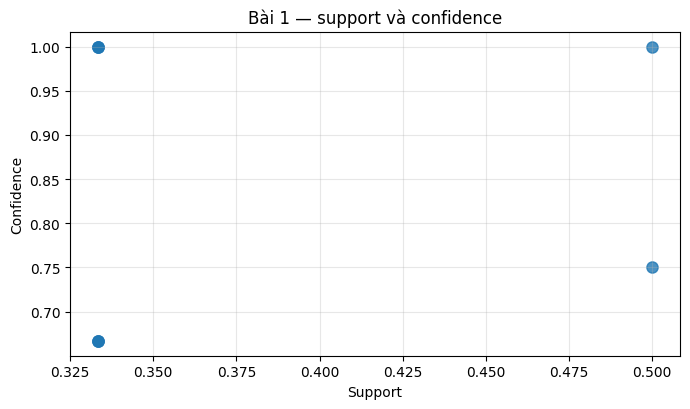

In [4]:
levels, counts=apriori_manual(transactions,min_count)
for k,lev in enumerate(levels,1):print(f'L{k}: {len(lev)} tập phổ biến')
display(itemsets_table(counts,len(transactions)))
rules=rules_from_counts(counts,transactions,min_conf)
print('Số luật hợp lệ:',len(rules));display(rules)
plot_rules(rules,'Bài 1 — support và confidence')
